# Netflix 1990s 電影分析（DataCamp 練習）

課程：DataCamp「探究 Netflix 電影」專案

工作區連結：https://www.datacamp.com/datalab/w/5f303524-ec26-4a41-9211-2560dcd78898/edit

## 讀入資料

In [1]:
# Importing pandas and matplotlib
import pandas as pd
import matplotlib.pyplot as plt

# Read in the Netflix CSV as a DataFrame
netflix_df = pd.read_csv("netflix_data.csv")

In [2]:
netflix_df.head()

,show_id,type,title,director,cast,country,date_added,release_year,duration,description,genre
0,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,93,After a devastating earthquake hits Mexico Cit...,Dramas
1,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,78,"When an army recruit is found dead, his fellow...",Horror Movies
2,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,80,"In a postapocalyptic world, rag-doll robots hi...",Action
3,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,123,A brilliant group of students become card-coun...,Dramas
4,s6,TV Show,46,Serdar Akar,"Erdal Beşikçioğlu, Yasemin Allen, Melis Birkan...",Turkey,"July 1, 2017",2016,1,A genetics professor experiments with a treatm...,International TV


In [3]:
netflix_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4812 entries, 0 to 4811
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       4812 non-null   str  
 1   type          4812 non-null   str  
 2   title         4812 non-null   str  
 3   director      4812 non-null   str  
 4   cast          4812 non-null   str  
 5   country       4812 non-null   str  
 6   date_added    4812 non-null   str  
 7   release_year  4812 non-null   int64
 8   duration      4812 non-null   int64
 9   description   4812 non-null   str  
 10  genre         4812 non-null   str  
dtypes: int64(2), str(9)
memory usage: 413.7 KB


## 篩選 1990s 電影
> `release_year` 是上映年份，不是上架年份

In [4]:
movies_1990s = netflix_df[
    (netflix_df['type'] == 'Movie') &
    (netflix_df['release_year'] >= 1990) &
    (netflix_df['release_year'] < 2000)
]
print(f"1990s 電影數量：{len(movies_1990s)}")

1990s 電影數量：183


## 最常見片長（mode）
> `mode()[0]` 遇到並列會取最小值，用 `value_counts()` 確認

In [5]:
duration = int(movies_1990s['duration'].mode()[0])
print(f"最常見片長 duration = {duration}")

最常見片長 duration = 94


In [6]:
movies_1990s['duration'].value_counts().head()

duration
94     7
101    6
108    5
95     5
93     5
Name: count, dtype: int64

## 片長分布

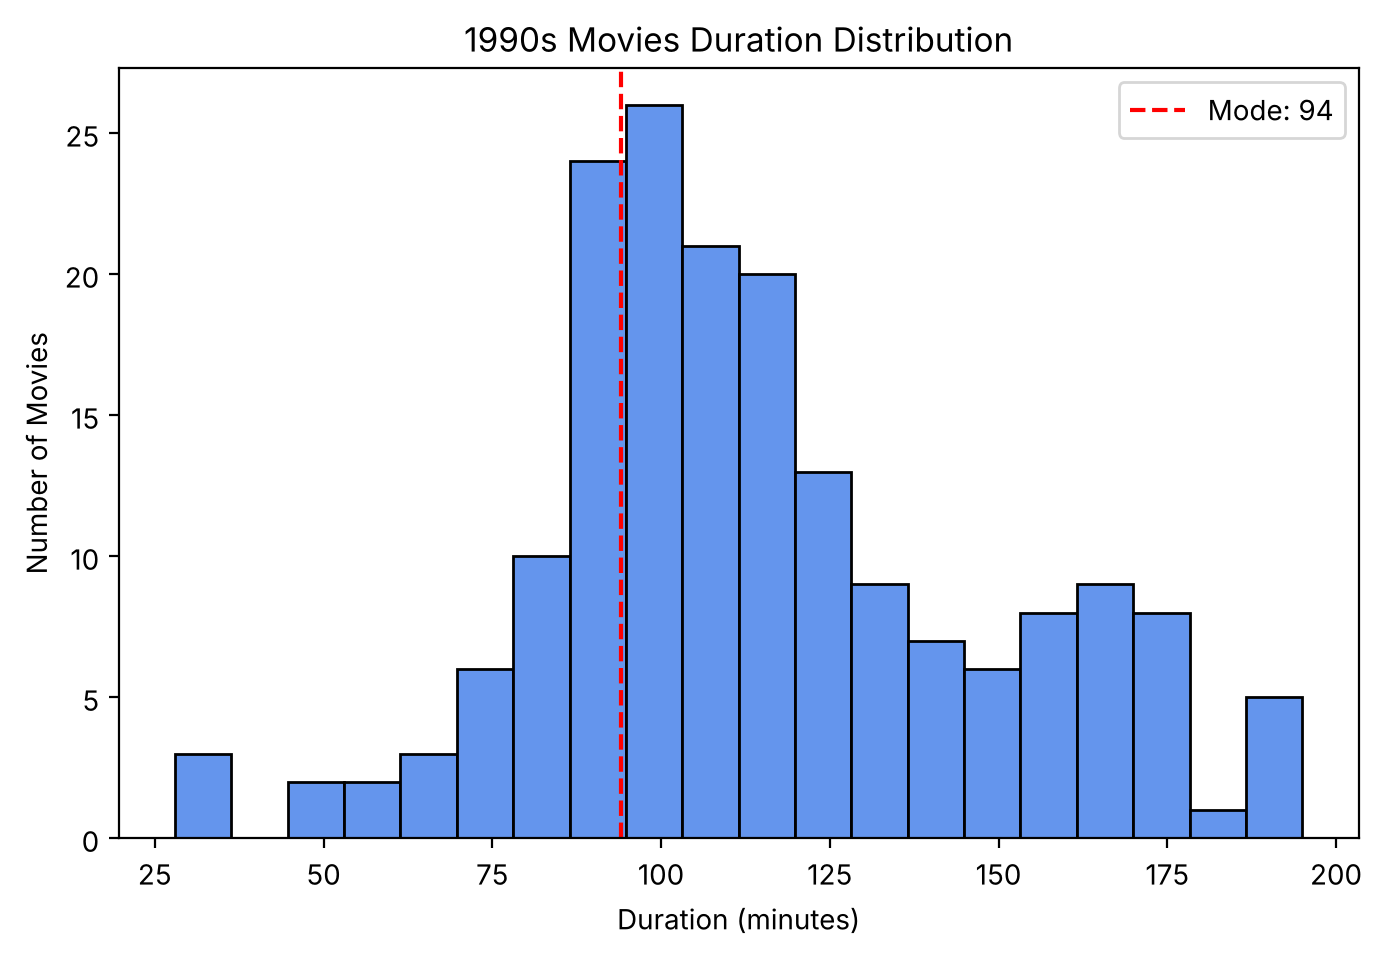

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(movies_1990s['duration'], bins=20, color='cornflowerblue', edgecolor='black')
plt.title('1990s Movies Duration Distribution')
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of Movies')
plt.axvline(duration, color='red', linestyle='--', label=f'Mode: {duration}')
plt.legend()
plt.show()

## 1990s 動作類短片數量（< 90 分鐘）

In [8]:
short_action_movies = movies_1990s[
    (movies_1990s['duration'] < 90) &
    (movies_1990s['genre'] == 'Action')
]
short_movie_count = len(short_action_movies)
print(f"short_movie_count = {short_movie_count}")

short_movie_count = 7


### 符合條件的電影

In [9]:
short_action_movies[['title', 'release_year', 'duration', 'genre']]

,title,release_year,duration,genre
1288,EVANGELION: DEATH (TRUE)²,1998,69,Action
1698,Hero,1997,89,Action
2328,"Look Out, Officer",1990,88,Action
2993,Passenger 57,1992,84,Action
3297,Rumble in the Bronx,1995,89,Action
3806,The Bare-Footed Kid,1993,83,Action
3943,The End of Evangelion,1997,87,Action
